# FACECAST

In this notebook we are going to build a network that takes a 16×16 picture of a face and produces a 128×128 picture of it. That is 8× upscaling per side, so the output has 64 times more pixels than the input. Most of the output cannot be *recovered* from the input, it has to be *invented* in a plausible way, which is why the task is called **face hallucination**. We are going to use the CelebA dataset and you can learn more about it [here](https://mmlab.ie.cuhk.edu.hk/projects/CelebA.html). For now, this notebook consists of the following steps:
* Environment setup
* Dataset download

The rest (baselines, the network, training and evaluation) will be added step by step.

### Step 0: Environment Setup

The dependencies are listed in `pyproject.toml` and managed by [uv](https://docs.astral.sh/uv/). Run `uv sync` once in the project folder, it creates the `.venv` environment with everything installed. Then select `.venv` as the kernel of this notebook.

Note that `pip` is not available in a uv environment, so `%pip install` does not work here. To add a new package, use `uv add <package>` in the terminal.

In [1]:
import os
# Folder for the downloads (has to be set before datasets is imported)
data_dir = os.path.abspath('data')
os.environ['HF_HOME'] = data_dir

import random
import numpy as np
import torch
import torchvision
import datasets
from datasets import load_dataset

from matplotlib import pyplot as plt
plt.rcParams['figure.figsize'] = [15, 10]

# Set the seed for reproducibility (python, numpy and torch)
random.seed(1234)
np.random.seed(1234)
torch.manual_seed(1234)

# Use the GPU if there is one
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

print('PyTorch:     ', torch.__version__)
print('Torchvision: ', torchvision.__version__)
print('Datasets:    ', datasets.__version__)
print('Data folder: ', data_dir)
print('Device:      ', device, '-', torch.cuda.get_device_name(0) if device.type == 'cuda' else 'no GPU found')

PyTorch:      2.11.0+cu128
Torchvision:  0.26.0+cu128
Datasets:     5.2.0
Data folder:  /home/anton/PycharmProjects/facecast/data
Device:       cuda - NVIDIA GeForce RTX 5090


### Step 1: Dataset Download

Download the CelebA dataset (aligned and cropped faces) from Hugging Face. Everything we download goes to the `data` folder (we pointed `HF_HOME` to it in the previous step), which is not tracked by git.

The download is about 11.7 GB and the prepared copy takes the same again, so you need about 24 GB of free space and the first run takes a while. The next runs find the files in `data` and load them right away.

In [2]:
# Download the dataset (or load it from the data folder if it is already there)
dataset = load_dataset('flwrlabs/celeba')

# The dataset comes with the official train / validation / test split
train_set, val_set, test_set = dataset['train'], dataset['valid'], dataset['test']

print('Train set:      ', len(train_set), 'samples')
print('Validation set: ', len(val_set), 'samples')
print('Test set:       ', len(test_set), 'samples')

Train set:       162770 samples
Validation set:  19867 samples
Test set:        19962 samples


Make a quick inspection to check that the download is fine.

Columns:     42 - ['image', 'celeb_id', '5_o_Clock_Shadow', 'Arched_Eyebrows'] ...
Image size:  (178, 218) RGB


Identities:  8192 in the train set


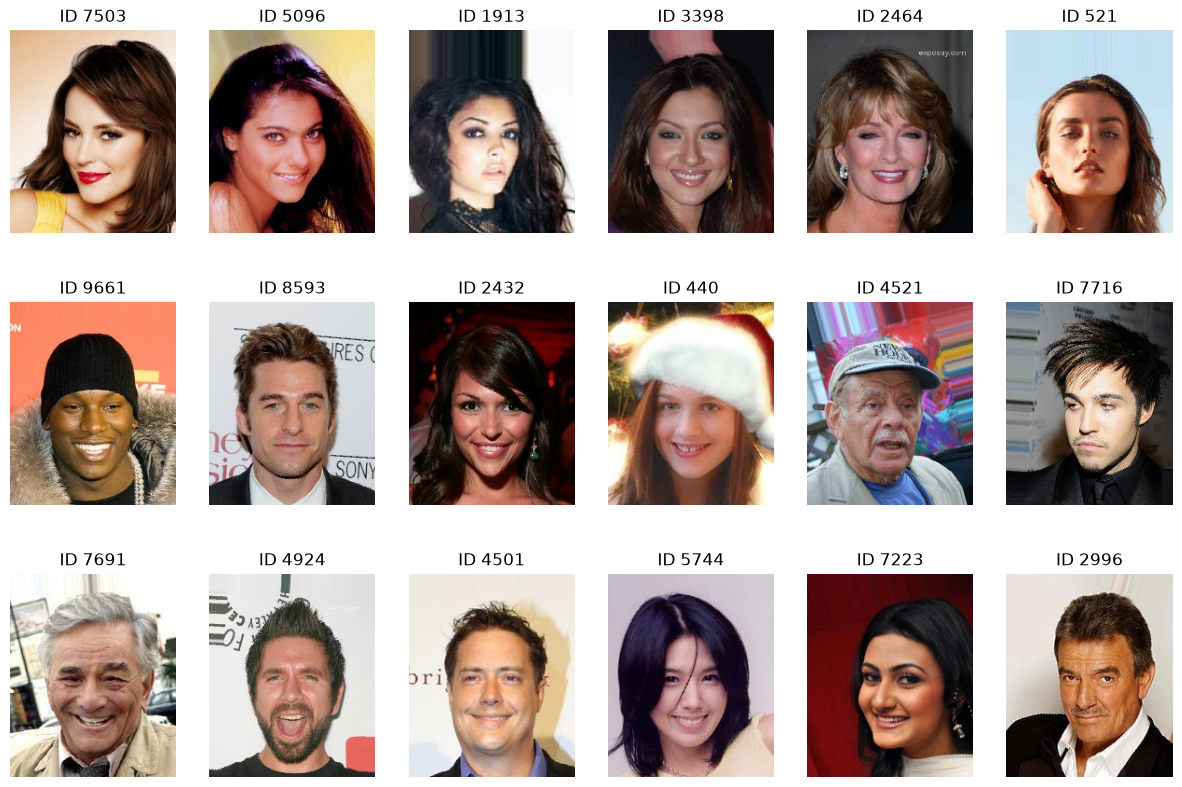

In [3]:
# Every sample is an image, the ID of the person and 40 binary attributes
sample = train_set[0]
print('Columns:    ', len(train_set.column_names), '-', train_set.column_names[:4], '...')
print('Image size: ', sample['image'].size, sample['image'].mode)
print('Identities: ', len(set(train_set['celeb_id'])), 'in the train set')

# Visualize random samples (as a plot with 3x6 samples)
for ii in range(18):
    plt.subplot(3,6,ii+1)
    # Pick a random sample
    idx = np.random.randint(0, len(train_set))
    # Show the image and the ID of the person
    plt.imshow(train_set[idx]['image'])
    plt.title('ID ' + str(train_set[idx]['celeb_id']))
    plt.axis('off')